#**Introduction to Tensorflow**
In this reading assignment, you'll be introduced to a different method to build a keras model. We will be using Tensorflow throughout the course as well.

##Prerequisites:


1.   Basics of Python Programming
2.   Basics of Object Oriented Programming
3.   Basics of tensorflow

##Learning Objectives:


1.   Learn to implement keras model in three different ways






<h1><b>Methods to build a keras model</b></h1>



*   Sequential
*   Functional API
*   Model Subclassing






<h2><b>Sequential Model</b></h2>

Sequential model is a linear stack of layers but you are limited to one input and output. Sequential model is best choice when you want simple stack by stack layer model. The first layer of sequential model need to know input shape of dataset.



In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [ ]:
model = Sequential([
  Dense(5, activation='relu',input_shape=(4,)),
  Dense(8,activation='relu'),
  Dense(3,activation='softmax')                  
])

In [ ]:
model.summary()

Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
dense (Dense)                (None, 5)                 25        
_________________________________________________________________
dense_1 (Dense)              (None, 8)                 48        
_________________________________________________________________
dense_2 (Dense)              (None, 3)                 27        
Total params: 100
Trainable params: 100
Non-trainable params: 0
_________________________________________________________________


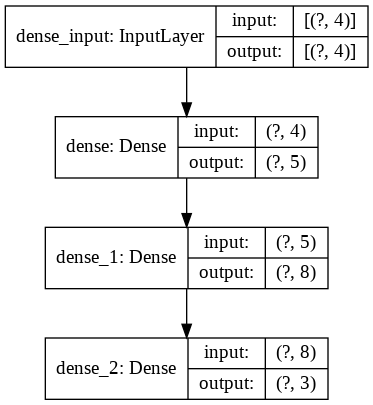

In [ ]:
import keras
keras.utils.plot_model(model, "my_first_model.png",show_shapes=True)

<h2><b>Functional API</b></h2>


The keras functional api deliver more flexible way to build model than sequential model. It can handle complex model, multiple input or output models as well as models that share layers.




First we need to define an input which return a tensor and passes to dense layers which also return tensors and in last layer it acts like a output. At last model is define by inputs and outputs tensor.




In [ ]:
from tensorflow.keras.layers import Input,Dense
from tensorflow.keras.models import Model

In [ ]:
inputs = Input(shape=(784,))
x = Dense(64,activation='relu')(inputs)
x = Dense(64,activation='relu')(x)
outputs = Dense(10,activation='softmax')(x)
model = Model(inputs=inputs,outputs=outputs)

In [ ]:
model.summary()

Model: "functional_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_1 (InputLayer)         [(None, 784)]             0         
_________________________________________________________________
dense_3 (Dense)              (None, 64)                50240     
_________________________________________________________________
dense_4 (Dense)              (None, 64)                4160      
_________________________________________________________________
dense_5 (Dense)              (None, 10)                650       
Total params: 55,050
Trainable params: 55,050
Non-trainable params: 0
_________________________________________________________________


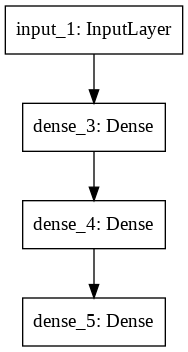

In [ ]:
keras.utils.plot_model(model, "my_first_model.png",show_shapes=True)

## **Multi inputs and outputs**

Scenario


*   One input and two output: if we only have image data and we need to find out that the image is flower or not. if it is a flower what kind of flower it is?



In [ ]:
from tensorflow.keras.layers import Dense, Input, concatenate
from tensorflow.keras.models import Model

In [ ]:
#Input layers
input = Input(shape=(64,))
# Middle layer
x = Dense(128,activation='relu')(input)
# output layer
output_layer_1 = Dense(3,activation='softmax',name='output_layer_1')(x)
output_layer_2 = Dense(1,activation='sigmoid',name='output_layer_2')(x)
# Define Model
model = Model(inputs=input,outputs=[output_layer_1,output_layer_2])

In [ ]:
model.summary()

Model: "functional_3"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_2 (InputLayer)            [(None, 64)]         0                                            
__________________________________________________________________________________________________
dense_6 (Dense)                 (None, 128)          8320        input_2[0][0]                    
__________________________________________________________________________________________________
output_layer_1 (Dense)          (None, 3)            387         dense_6[0][0]                    
__________________________________________________________________________________________________
output_layer_2 (Dense)          (None, 1)            129         dense_6[0][0]                    
Total params: 8,836
Trainable params: 8,836
Non-trainable params: 0
___________________

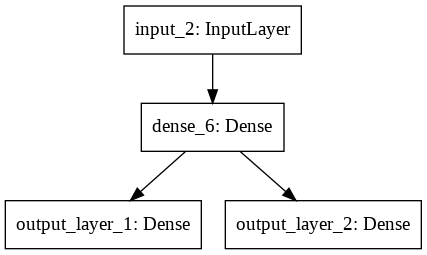

In [ ]:
import keras
keras.utils.plot_model(model, "my_first_model.png")

*   Two input and one output: if we only have image data and structured data and we need to find out that what kind of flower is it?


In [ ]:
#Input layers
input_1 = Input(shape=(784,),name = 'Input_Image_data')
input_2 = Input(shape=(4,),name='Input_Structured_data')
# Middle layer
x_1 = Dense(10,activation='relu')(input_1)
x_2 = Dense(64,activation='relu')(input_2)
#Concatenate
c = concatenate([x_1,x_2])
# output layer
output_layer = Dense(3,activation='softmax',name='output_layer_1')(c)
# Define Model
model = Model(inputs=[input_1,input_2],outputs=output_layer)

In [ ]:
model.summary()

Model: "functional_5"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
Input_Image_data (InputLayer)   [(None, 784)]        0                                            
__________________________________________________________________________________________________
Input_Structured_data (InputLay [(None, 4)]          0                                            
__________________________________________________________________________________________________
dense_7 (Dense)                 (None, 10)           7850        Input_Image_data[0][0]           
__________________________________________________________________________________________________
dense_8 (Dense)                 (None, 64)           320         Input_Structured_data[0][0]      
_______________________________________________________________________________________

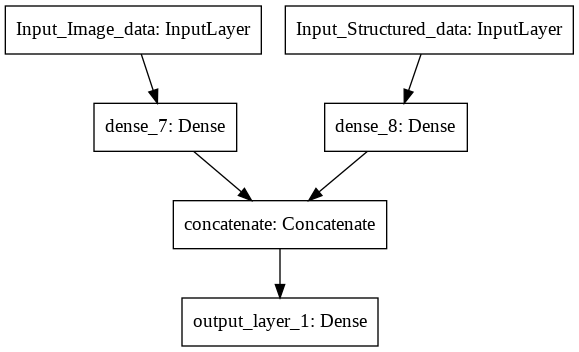

In [ ]:
keras.utils.plot_model(model)


 **Two input and Two output**: If we only have image data and structured data and we need to find out the image is flower or not. if it is a flower what kind of flower it is?


In [ ]:
#Input layers
input_1 = Input(shape=(784,),name = 'Input_Image_data')
input_2 = Input(shape=(4,),name='Input_Structured_data')
# Middle layer
x_1 = Dense(10,activation='relu')(input_1)
x_2 = Dense(64,activation='relu')(input_2)
#Concatenate
c = concatenate([x_1,x_2])
# output layer
output_layer_1 = Dense(3,activation='softmax',name='output_layer_1')(c)
output_layer_2 = Dense(1,activation='sigmoid',name='output_layer_2')(c)

# Define Model
model = Model(inputs=[input_1,input_2],outputs=[output_layer_1,output_layer_2])

In [ ]:
model.summary()

Model: "functional_7"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
Input_Image_data (InputLayer)   [(None, 784)]        0                                            
__________________________________________________________________________________________________
Input_Structured_data (InputLay [(None, 4)]          0                                            
__________________________________________________________________________________________________
dense_9 (Dense)                 (None, 10)           7850        Input_Image_data[0][0]           
__________________________________________________________________________________________________
dense_10 (Dense)                (None, 64)           320         Input_Structured_data[0][0]      
_______________________________________________________________________________________

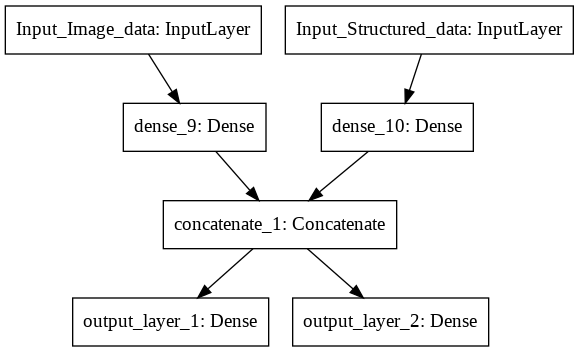

In [ ]:
keras.utils.plot_model(model)

<h2><b>Shared layer</b></h2>

One of the benefit to use functional api models because it allows to define shared layers. Shared layers are layer instances that are reused multiple times in the same model. As you can see in implementation, to share a layer in the functional API we call the same layer instance multiple times.


In [ ]:
#Input layer
inputs = Input(shape=(64,), name='input_layer')
# Sharable layer
share_layer = Dense(64,activation='relu',name='share_layer')
# Now we apply the layer twice
x = share_layer(inputs)
x = share_layer(x)
x = share_layer(x)
# Output layer
output_layer = Dense(10,activation='softmax',name='output_layer')(x)
# Define model
model = Model(inputs=inputs,outputs=output_layer) 
model.summary()

Model: "functional_14"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_layer (InputLayer)        [(None, 64)]         0                                            
__________________________________________________________________________________________________
share_layer (Dense)             (None, 64)           4160        input_layer[0][0]                
                                                                 share_layer[0][0]                
                                                                 share_layer[1][0]                
__________________________________________________________________________________________________
output_layer (Dense)            (None, 10)           650         share_layer[2][0]                
Total params: 4,810
Trainable params: 4,810
Non-trainable params: 0
__________________

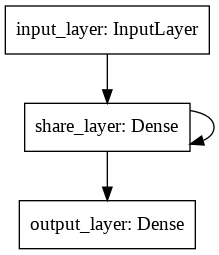

In [ ]:
keras.utils.plot_model(model)

<h2><b>Model Subclassing</b></h2>

The last method to build the keras model is called model subclassing. Model subclassing is completely customizable and allows us to build our own custom forward-pass of the model. In Keras the Model class is the root class used to define a model architecture. In model subclassing implementation, MyModel inherits from the Model class. The structure of model subclassing is that we create layers in the initializer __init__() and define the forward pass in the call() method.

<center>
<figure>


<p>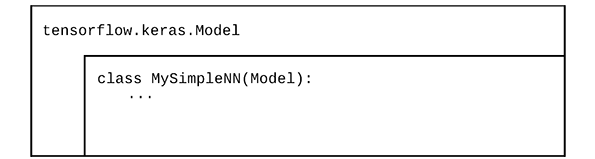</p>
<figcaption align="center">Model Subclassing</figcaption>
</figure>
</center>


In [ ]:
# MyModel inherits from the model class
class MyModel(Model):
  #Initialize the layers
  def __init__(self,**kwargs):
    super(MyModel,self).__init__(**kwargs)
    self.dense1 = Dense(16,activation='relu')
    self.dense2 = Dense(32,activation='relu')
    self.dense3 = Dense(5,activation='softmax')
  # Forward pass
  def call(self,inputs):
    x = self.dense1(inputs)
    x = self.dense2(x)
    x = self.dense3(x)
    return x

In [ ]:
model = MyModel()
model.build(input_shape=(4,4))

In [ ]:
model.summary()

Model: "my_model"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
dense_3 (Dense)              multiple                  80        
_________________________________________________________________
dense_4 (Dense)              multiple                  544       
_________________________________________________________________
dense_5 (Dense)              multiple                  165       
Total params: 789
Trainable params: 789
Non-trainable params: 0
_________________________________________________________________


##Key Takeaways:


1.   Learn to implement keras model in three different ways
2.   Sequential model is used for implementing simple stacking layers, Functional api is used for implementing complex models like multiple inputs and outputs, sharable layers and Model subclassing allows us to build our own custom model. 


